# Данные Даши: состояние = тяжесть обвинения

Отдельный эксперимент Этапа 1. Журнал строится не по таблице этапа 0, а по таблице Даши
`individual_custody_timeline_rfm.csv` (18 668 заключений). Состояние процесса — **степень тяжести обвинения**
(F1, F2, F3, …, M1, M2), а не тип преступления.

**Проблема исходной колонки.** В таблице Даши `c_charge_degree` у 99% людей одна и та же во всех заключениях: это
обвинение из дела COMPAS, скопированное в каждую строку. Граф по ней состоит только из петель X → X (шаг 3).
Поэтому основной вариант берёт тяжесть **для каждого заключения отдельно** из `compas.db`: самое тяжёлое обвинение
ареста, с которого началось заключение (правила в `dasha_severity.py`, те же, что в `stage1/build_episode_charges.py`).
Колонка Даши как есть считается рядом для сравнения.

**Состояния (7).** `F1`, `F2`, `F3`, `F_other` (F5, F6, F7 — 47 заключений), `M1`, `M2` (M2 и MO3), `Unknown`
(обвинение не найдено или редкий код: CO3, NI0, 0).

**Журнал.** Одно событие на заключение, время = вход в заключение. Кейс — человек (`person_id` из compas.db, если
нашёлся, иначе имя). Заключения без даты входа выброшены. Состояния END нет: последнее заключение каждого человека
цензурировано (наблюдение до 2016-04-19).

**Как запустить.** Окружение `D:\Git\diploma\.venv`, открыть ноутбук из этой папки, *Run All*. Входы: таблица Даши
(`data\individual_custody_timeline_rfm.csv` рядом с ноутбуком или `D:\Git\diploma\recurrent_event\data\…`) и
`jupyter lab\stage0 - data\compas.db`. Результаты пишутся в `out\`.

## Шаг 0. Настройки

In [1]:
import os, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

warnings.filterwarnings("ignore")
os.environ["PM4PY_SHOW_PROGRESS_BAR"] = "False"
for gv in [Path(r"D:\Graphviz\bin")]:
    if gv.exists() and str(gv) not in os.environ["PATH"]:
        os.environ["PATH"] = str(gv) + os.pathsep + os.environ["PATH"]
import pm4py
import dasha_severity as S

HERE = Path.cwd()
ROOT = HERE.parent.parent                       # jupyter lab (на компьютере) или корень репозитория
first = lambda c: next((p for p in c if p.exists()), c[0])
DASHA = first([HERE / "data" / "individual_custody_timeline_rfm.csv",
               Path(r"D:\Git\diploma\recurrent_event\data\individual_custody_timeline_rfm.csv")])
DB = first([ROOT / "stage0 - data" / "compas.db", ROOT / "stage0-data" / "compas.db"])
OUT = HERE / "out"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

MODELS = ["HM_0.5", "HM_0.9", "HM_0.95", "IM_0.0", "IM_0.2", "IM_0.5"]
EVAL_CASES = 2000           # людей в выборках train/test для fitness/precision
ALIGN_CASES = 2000          # precision через выравнивания для HM 0.9 (0 — не считать)
print("pm4py", pm4py.__version__)
print("таблица Даши:", DASHA, DASHA.exists())
print("compas.db:", DB, DB.exists())


def show(path, max_px=1400):
    from io import BytesIO
    from PIL import Image as PILImage
    im = PILImage.open(path)
    im.thumbnail((max_px, max_px))
    buf = BytesIO()
    im.convert("RGB").save(buf, format="JPEG", quality=85)
    display(Image(data=buf.getvalue(), format="jpeg"))



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




pm4py 2.7.23.9
таблица Даши: /tmp/claude-0/w/exproot/stage1/dasha_severity/data/individual_custody_timeline_rfm.csv True
compas.db: /tmp/claude-0/w/exproot/stage0 - data/compas.db True


## Шаг 1. Тяжесть каждого заключения

Для каждой строки таблицы Даши ищется человек в `compas.db` и обвинения ареста, с которого началось заключение;
из них берётся самое тяжёлое. Расчёт занимает около минуты.

In [2]:
dasha = pd.read_csv(DASHA)
t0 = time.time()
ep = S.episode_degree(dasha, DB)
print(f"готово за {time.time() - t0:.0f} с, заключений {len(ep)}")
print("\nОткуда взято обвинение:")
print(ep["ep_charge_source"].value_counts().to_string())
dated = ep["in_custody"].notna()
same = (ep.loc[dated, "ep_charge_degree"].fillna("-") == ep.loc[dated, "c_charge_degree"].fillna("-")).mean()
print(f"\nТяжесть по заключению совпадает с колонкой Даши в {same:.1%} заключений")
print("Людей, у которых тяжесть в колонке Даши меняется между заключениями:",
      int((ep.groupby("name")["c_charge_degree"].nunique() > 1).sum()), "из", ep["name"].nunique())

готово за 53 с, заключений 18668

Откуда взято обвинение:
ep_charge_source
arrest        15936
none           1682
prior_case      991
offense          59

Тяжесть по заключению совпадает с колонкой Даши в 68.1% заключений
Людей, у которых тяжесть в колонке Даши меняется между заключениями: 77 из 10855


In [3]:
pd.crosstab(ep.loc[dated, "c_charge_degree"].map(S.to_state).rename("колонка Даши"),
            ep.loc[dated, "ep_charge_degree"].map(S.to_state).rename("по заключению")
            ).reindex(index=S.STATE_ORDER, columns=S.STATE_ORDER, fill_value=0)

по заключению,F1,F2,F3,F_other,M1,M2,Unknown
колонка Даши,,,,,,,
F1,219,25,20,1,7,5,17
F2,90,1127,149,1,94,29,53
F3,279,1630,7165,2,681,384,247
F_other,31,55,55,41,14,7,12
M1,41,184,384,2,2874,121,122
M2,20,93,220,0,484,399,154
Unknown,2,0,12,0,4,9,509


## Шаг 2. Журнал событий (два варианта)

In [4]:
LOGS = {"по заключению": S.build_log(ep, "ep_charge_degree"),
        "колонка Даши": S.build_log(ep, "c_charge_degree")}
log = LOGS["по заключению"]
log.to_csv(OUT / "event_log_dasha_severity.csv", index=False)
LOGS["колонка Даши"].to_csv(OUT / "event_log_dasha_column.csv", index=False)
log.head(10)

,case:concept:name,concept:name,time:timestamp,out_custody,ep_row,name,person_id,ep_charge_degree
0,p1,F3,2013-08-13,2013-08-14,12889,miguel hernandez,1,(F3)
1,p1,F3,2014-07-07,2014-07-14,12890,miguel hernandez,1,(F3)
2,p10,M1,2014-03-15,2014-03-18,5606,elizabeth thieme,10,(M1)
3,p100,M1,2013-09-28,2013-10-01,12382,merlita hanson,100,(M1)
4,p1000,F3,2014-11-05,2014-12-30,8245,jeffrey forrest,1000,(F3)
5,p1000,F3,2015-01-16,2015-02-19,8246,jeffrey forrest,1000,(F3)
6,p1000,F3,2016-02-09,NaT,8247,jeffrey forrest,1000,(F3)
7,p10000,M1,2014-05-31,2014-06-02,9689,juan crespo,10000,(M1)
8,p10001,M1,2014-10-24,2014-10-25,15423,sabra mitchell,10001,(M1)
9,p10002,Unknown,2013-01-04,2013-01-05,13622,pancia gerald,10002,NaN


## Шаг 3. Статистика

Доля петель X → X — доля переходов между соседними заключениями человека, в которых тяжесть не меняется.

In [5]:
stats = pd.DataFrame({k: S.log_stats(v) for k, v in LOGS.items()})
stats.to_csv(OUT / "log_stats.csv")
stats

,по заключению,колонка Даши
состояний,7.000,7.0
людей,10406.000,10406.0
событий,18074.000,18074.0
людей с 1 заключением,6193.000,6193.0
переходов,7668.000,7668.0
дуг DFG,42.000,8.0
доля петель X→X,0.662,1.0
вариантов трасс,518.000,58.0
людей с уникальной трассой,313.000,8.0


In [6]:
freq = pd.DataFrame({k: v["concept:name"].value_counts() for k, v in LOGS.items()}).reindex(S.STATE_ORDER).fillna(0).astype(int)
freq.to_csv(OUT / "state_counts.csv")
freq

,по заключению,колонка Даши
concept:name,,
F1,682,294
F2,3114,1543
F3,8005,10388
F_other,47,215
M1,4158,3728
M2,954,1370
Unknown,1114,536


Матрица переходов (по заключению): строка — тяжесть текущего заключения, столбец — следующего, доли по строке.

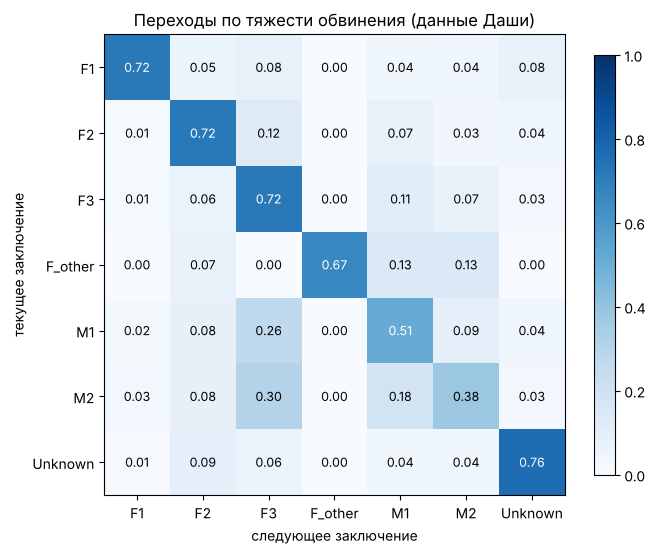

In [7]:
pairs = S.liberty_pairs(log)
cnt = pd.crosstab(pairs["concept:name"], pairs["nxt"]).reindex(index=S.STATE_ORDER, columns=S.STATE_ORDER, fill_value=0)
prob = cnt.div(cnt.sum(axis=1), axis=0).round(3)
cnt.to_csv(OUT / "transition_counts.csv")
prob.to_csv(OUT / "transition_probs.csv")

fig, ax = plt.subplots(figsize=(7, 6))
im_ = ax.imshow(prob.values, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(prob.columns)), prob.columns)
ax.set_yticks(range(len(prob.index)), prob.index)
for i in range(prob.shape[0]):
    for j in range(prob.shape[1]):
        v = prob.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if v > 0.5 else "black", fontsize=9)
ax.set_xlabel("следующее заключение"); ax.set_ylabel("текущее заключение")
ax.set_title("Переходы по тяжести обвинения (данные Даши)")
fig.colorbar(im_, ax=ax, shrink=0.8)
fig.tight_layout()
fig.savefig(FIG / "transition_matrix.png", dpi=120)
plt.show()

## Шаг 4. Граф в PM4Py

### 4.1 DFG по частоте

Состояний всего 7, поэтому DFG рисуется целиком, без фильтра путей.

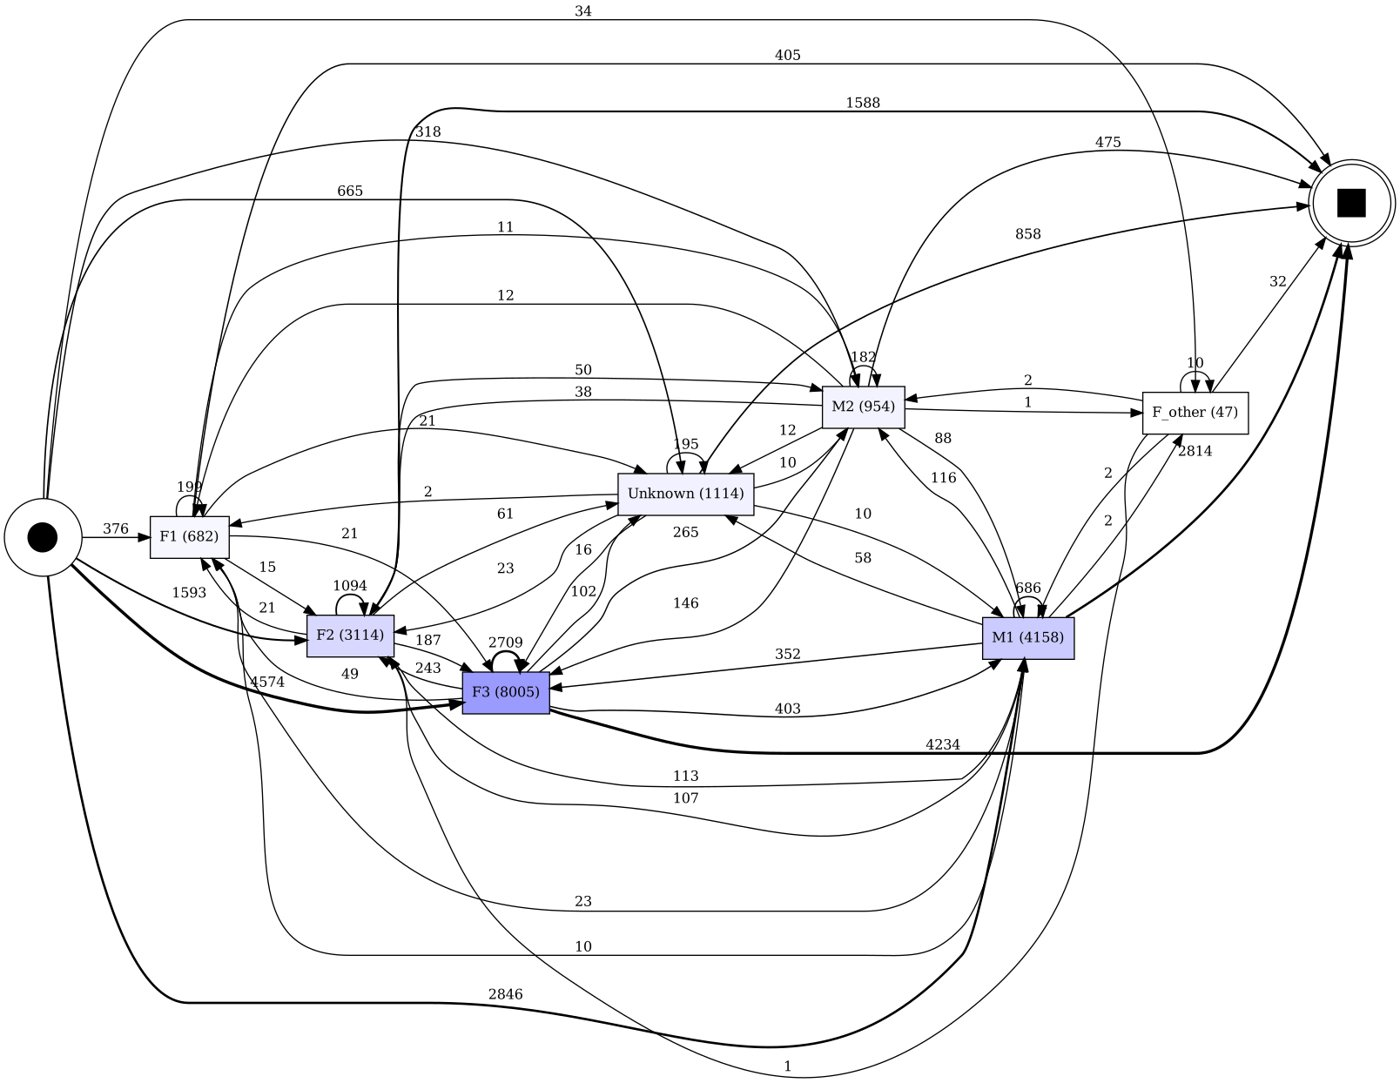

In [8]:
pm_log = pm4py.format_dataframe(log[["case:concept:name", "concept:name", "time:timestamp"]].copy(),
                                case_id="case:concept:name", activity_key="concept:name", timestamp_key="time:timestamp")
dfg, sa, ea = pm4py.discover_dfg(pm_log)
pd.Series(dfg).rename("переходов").rename_axis(["из", "в"]).sort_values(ascending=False).to_csv(OUT / "dfg_arcs.csv")
pm4py.save_vis_dfg(dfg, sa, ea, str(FIG / "dfg_frequency.png"))
show(FIG / "dfg_frequency.png")

### 4.2 DFG по времени

Время на дуге — **время на свободе**: от выхода из заключения A до входа в следующее заключение B (медиана, дни).
Отрицательные интервалы (пересечение заключений в данных) приравнены к 0. У Даши `out_custody = 2020-01-01` означает
«ещё в заключении», такие интервалы не считаются.

Медиана времени на свободе по всем переходам: 132 дней


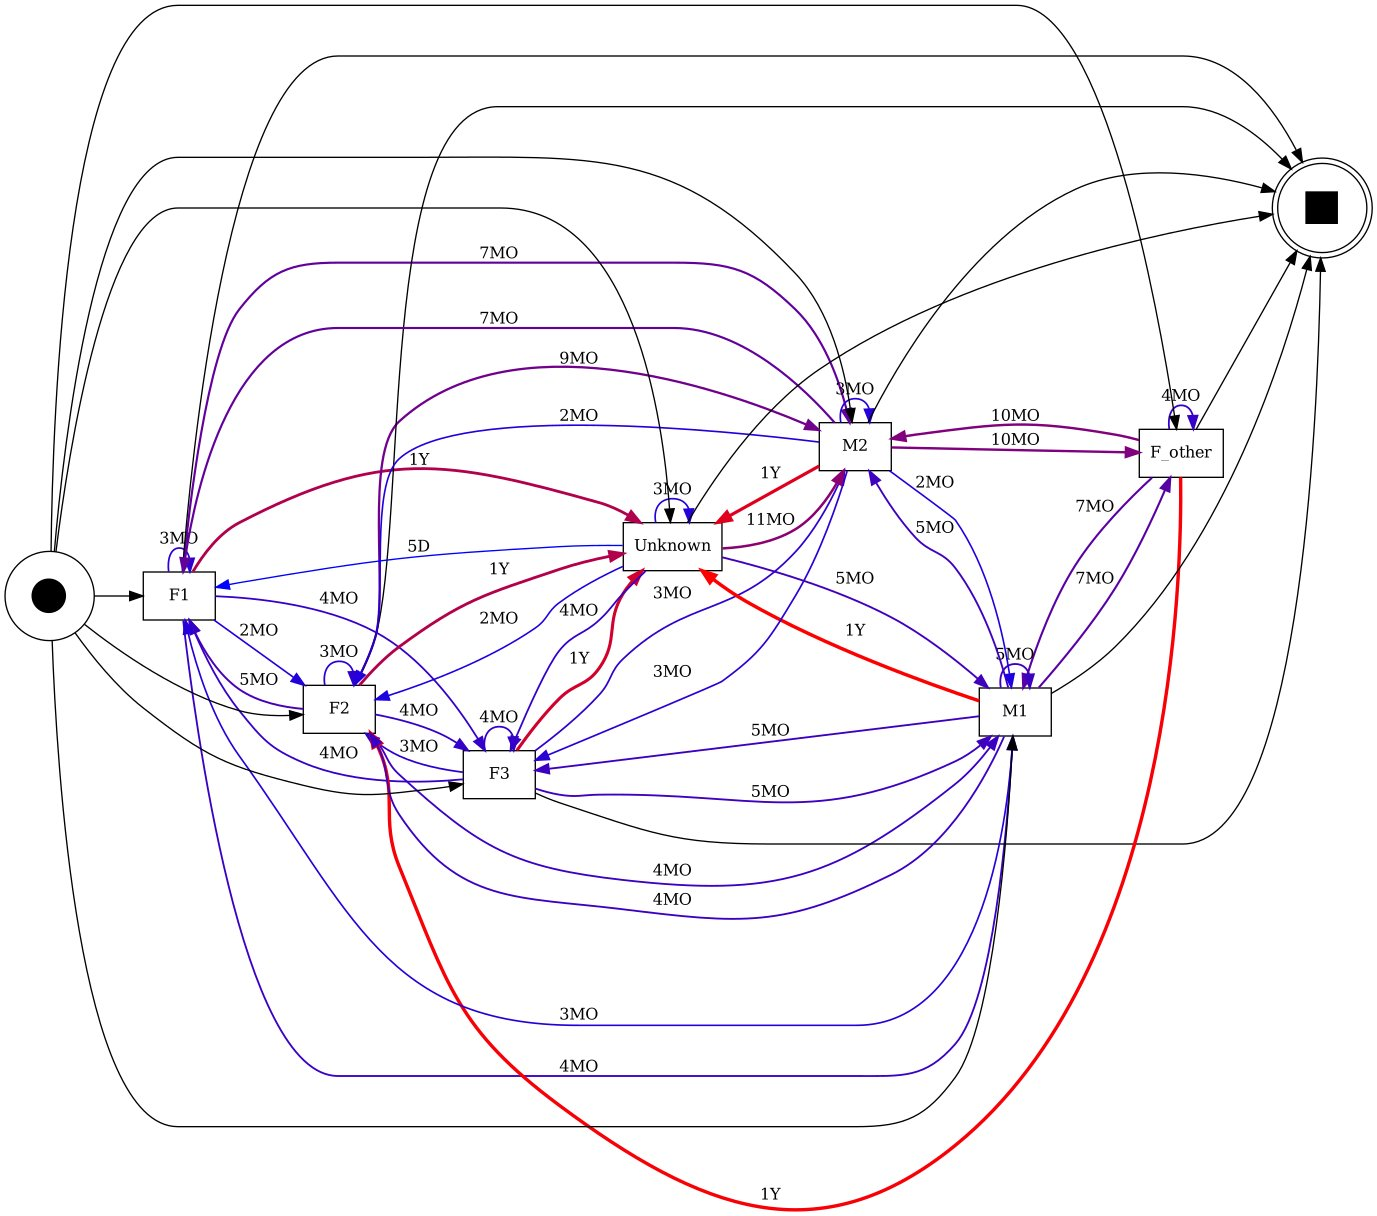

In [9]:
agg = pairs.dropna(subset=["days"]).assign(sec=lambda x: x["days"] * 86400) \
           .groupby(["concept:name", "nxt"])["sec"].agg(["mean", "median", "max", "min", "sum", "std"]).fillna(0)
perf = {k: dict(mean=r["mean"], median=r["median"], max=r["max"], min=r["min"], sum=r["sum"], stdev=r["std"])
        for k, r in agg.iterrows()}
perf = {k: perf.get(k, dict(mean=0, median=0, max=0, min=0, sum=0, stdev=0)) for k in dfg}
pm4py.save_vis_performance_dfg(perf, sa, ea, str(FIG / "dfg_performance.png"), aggregation_measure="median")
times = (agg[["median", "mean"]] / 86400).round(0).rename(columns={"median": "медиана, дни", "mean": "среднее, дни"})
times.to_csv(OUT / "dfg_times_liberty.csv")
print("Медиана времени на свободе по всем переходам:", round(pairs["days"].median()), "дней")
show(FIG / "dfg_performance.png")

### 4.3 Сети Петри: Heuristics Miner и Inductive Miner

Модели строятся на всём журнале «по заключению» для рисунков; качество — в 4.4.

HM 0.9: мест 16, переходов 57


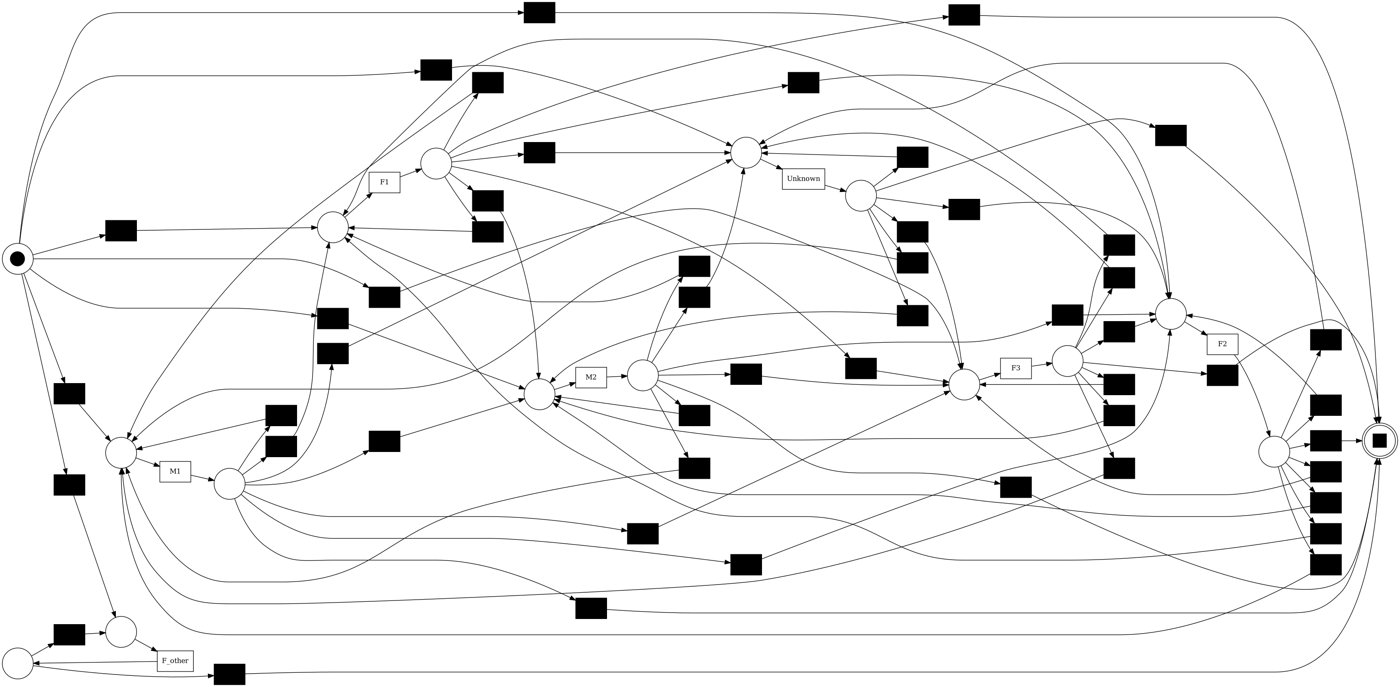

In [10]:
net, im, fm = pm4py.discover_petri_net_heuristics(pm_log, dependency_threshold=0.9)
pm4py.save_vis_petri_net(net, im, fm, str(FIG / "petri_HM_dep0.9.png"))
print(f"HM 0.9: мест {len(net.places)}, переходов {len(net.transitions)}")
show(FIG / "petri_HM_dep0.9.png")

Дерево процесса IM 0.2: +( X( tau, *( 'M2', tau ) ), X( tau, *( 'M1', tau ) ), X( tau, *( 'F_other', tau ), *( 'F3', tau ), *( 'Unknown', tau ), *( 'F1', tau ), *( 'F2', tau ) ) )


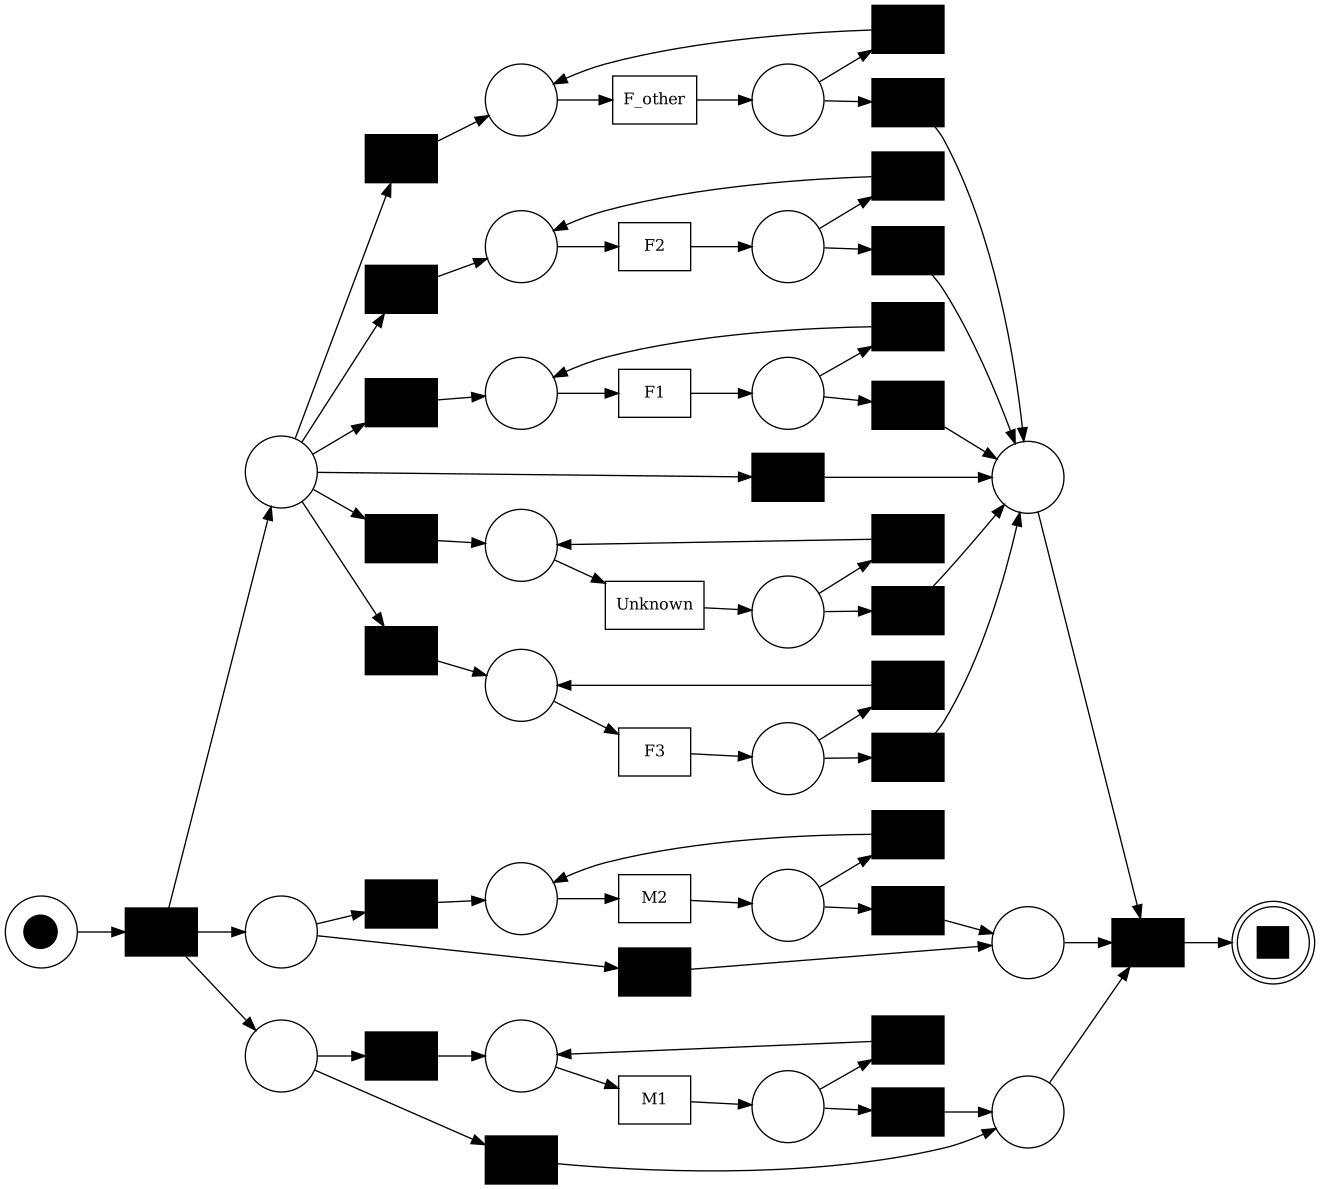

In [11]:
tree = pm4py.discover_process_tree_inductive(pm_log, noise_threshold=0.2)
net_i, im_i, fm_i = pm4py.convert_to_petri_net(tree)
pm4py.save_vis_petri_net(net_i, im_i, fm_i, str(FIG / "petri_IM_noise0.2.png"))
print("Дерево процесса IM 0.2:", tree)
show(FIG / "petri_IM_noise0.2.png")

### 4.4 Качество моделей

Как в экспериментах x2: люди делятся на train 80% / test 20% (seed 42), модели строятся на train, fitness и
precision (token-based replay) считаются на первых 2 000 людях train и test. Для HM 0.9 на журнале «по заключению»
дополнительно precision через выравнивания. Оба журнала оцениваются одинаково.

In [12]:
def discover(name, lg):
    kind, v = name.split("_")
    if kind == "HM":
        return pm4py.discover_petri_net_heuristics(lg, dependency_threshold=float(v))
    return pm4py.discover_petri_net_inductive(lg, noise_threshold=float(v))


rows = []
for variant, lg in LOGS.items():
    lg = pm4py.format_dataframe(lg[["case:concept:name", "concept:name", "time:timestamp"]].copy(),
                                case_id="case:concept:name", activity_key="concept:name", timestamp_key="time:timestamp")
    train, test = S.split_people(lg)
    train_s, test_s = S.sample_cases(train, EVAL_CASES), S.sample_cases(test, EVAL_CASES)
    models = {m: discover(m, train) for m in MODELS}
    q = S.evaluate(models, train_s, test_s).assign(variant=variant)
    if ALIGN_CASES and variant == "по заключению":
        pa = pm4py.precision_alignments(S.sample_cases(test, ALIGN_CASES), *models["HM_0.9"])
        q.loc[(q["model"] == "HM_0.9") & (q["split"] == "test"), "precision_align"] = round(pa, 4)
    rows.append(q)
quality = pd.concat(rows, ignore_index=True)
quality.to_csv(OUT / "model_quality.csv", index=False)
quality[quality["split"] == "test"].set_index(["variant", "model"]).drop(columns=["split"])

cases  fitness_tbr  pct_fit_traces  precision_tbr  \
variant       model                                                        
по заключению HM_0.5    2000       0.9944           97.00         0.9515   
              HM_0.9    2000       0.9984           99.15         0.9367   
              HM_0.95   2000       0.9981           99.00         0.9273   
              IM_0.0    2000       1.0000          100.00         0.8748   
              IM_0.2    2000       0.9936           93.10         0.9617   
              IM_0.5    2000       0.9432           66.35         0.9617   
колонка Даши  HM_0.5    2000       1.0000          100.00         1.0000   
              HM_0.9    2000       1.0000          100.00         1.0000   
              HM_0.95   2000       1.0000          100.00         1.0000   
              IM_0.0    2000       1.0000          100.00         0.9482   
              IM_0.2    2000       0.9894           91.80         0.9405   
              IM_0.5    2000       0.9894           91.80         0.9405   

                           f1  places  transitions  silent  sec  \
variant       model                                               
по заключению HM_0.5   0.9725      17           51      44    0   
              HM_0.9   0.9666      16           54      47    0   
              HM_0.95  0.9614      14           50      44    1   
              IM_0.0   0.9332      33           44      37    1   
              IM_0.2   0.9774      22           33      26    0   
              IM_0.5   0.9523      22           32      25    1   
колонка Даши  HM_0.5   1.0000      16           28      21    0   
              HM_0.9   1.0000      16           28      21    0   
              HM_0.95  1.0000      16           28      21    0   
              IM_0.0   0.9734      19           32      25    0   
              IM_0.2   0.9643      19           31      24    0   
              IM_0.5   0.9643      19           31      24    0   

                       precision_align  
variant       model                     
по заключению HM_0.5               NaN  
              HM_0.9            0.9367  
              HM_0.95              NaN  
              IM_0.0               NaN  
              IM_0.2               NaN  
              IM_0.5               NaN  
колонка Даши  HM_0.5               NaN  
              HM_0.9               NaN  
              HM_0.95              NaN  
              IM_0.0               NaN  
              IM_0.2               NaN  
              IM_0.5               NaN

## Итоги

**Колонка Даши как состояние не годится.** Тяжесть в `c_charge_degree` меняется между заключениями только у 77 из
10 855 человек, поэтому все 7 668 переходов — петли X → X, в DFG 8 дуг, HM даёт fitness = precision = 1
и ничего не говорят о процессе. С тяжестью, найденной для каждого заключения, она совпадает только в 68% заключений.

**Тяжесть по заключению** (основной вариант): 7 состояний, 18 074 события у 10 406 человек, 42 дуги DFG.
- Петли X → X — 66% переходов: чаще всего человек снова попадает с обвинением той же тяжести
  (F1, F2, F3 — около 0.72, M1 — 0.51, M2 — 0.38).
- Самые заметные смены: M2 → F3 (0.31), M1 → F3 (0.26), M2 → M1 (0.18), F2 → F3 (0.12), F3 → M1 (0.11).
  То есть после мисдиминора человек нередко возвращается уже с фелонией 3-й степени.
- Медиана времени на свободе между заключениями — 132 дня (в варианте «категории × 2» — 124).

**Модели** (test, token-based replay):

| модель | fitness | precision |
|---|---|---|
| HM 0.5 | 0.994 | 0.952 |
| HM 0.9 | 0.998 | 0.937 (выравнивания 0.937) |
| HM 0.95 | 0.998 | 0.927 |
| IM 0.0 | 1.000 | 0.875 |
| IM 0.2 | 0.994 | 0.962 |
| IM 0.5 | 0.943 | 0.962 |

Precision здесь намного выше, чем в вариантах с типом преступления (0.54–0.83), но сравнивать напрямую нельзя:
состояний всего 7, у 60% людей одно заключение (трасса из одного события), а в таблице Даши только заключения
вокруг дела COMPAS (18 668 против 22 552 в таблице этапа 0). Дерево IM 0.2 — параллельные независимые петли
по каждой тяжести; оно почти ничего не говорит о порядке, хотя precision высокая. Для графа переходов
лучше смотреть HM 0.9 и матрицу переходов.